In [1]:
# --- project root: run this notebook from anywhere inside the project folder
import os, sys
from pathlib import Path
_p = Path.cwd()
while not (_p / "preprocess.py").exists() and _p != _p.parent:
    _p = _p.parent
os.chdir(_p); sys.path.insert(0, str(_p))
print("working folder:", _p)

working folder: Map_Classification


# Final model — SegFormer v8 (Sentinel-1 only, 12 months)

This notebook brings together everything about the **final model** used by the prototype:
what it is, how it trained, how well it does on validation and test, where it is strong and weak,
and how it compares with the earlier models. It reads the results saved during training
(`runs/C_segformer_v8_border/`, notebook `r8_label_borders/19_train_v8_border_ignore`), so it runs on a laptop without a GPU.

| | |
|---|---|
| **Input** | 12 monthly Sentinel-1 composites (VV, VH, VV−VH, dB), 10 m pixels |
| **Classes** | Trees, Grass/Shrub, Cropland, Built-up, Bare, Water, Wetland (labels: ESA WorldCover 2021) |
| **Network** | temporal encoder over the 12 months (per pixel) + 18 year statistics → 1 × 1 fusion → SegFormer MiT-B2 |
| **Training data** | 38 training regions (950 tiles of 256 × 256 px), `data_r5` |
| **Special step** | label borders (pixels within 1 px of another class) ignored in training |
| **Evaluation** | 8 validation regions (128 tiles) and 6 test regions (96 tiles), every tile × 12 months, full labels |
| **Weights** | `runs/C_segformer_v8_border/best.pth` (99 MB) — from Zenodo, [`weights_final.zip`](https://zenodo.org/records/24060094/files/weights_final.zip?download=1) |

In [2]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from preprocess import CLASSES, COLORS

RUN = Path("runs/C_segformer_v8_border")
cfg = json.load(open(RUN / "config.json"))
M = json.load(open(RUN / "metrics.json"))
hist = pd.read_csv(RUN / "history.csv")
pd.Series({k: v for k, v in cfg.items()}).to_frame("training settings")

,training settings
RUN_NAME,C_segformer_v8_border
MODEL_NAME,SegFormer v8 (v6 + label borders ignored)
ARCH,temporal_segformer_mitb2
FEATURES,12months+yearstats18+border_ignore
DATA,data_r5
WEIGHTS,imagenet
EPOCHS,60
WARMUP_EPOCHS,5
BATCH_SIZE,8
EVAL_BATCH,2


## 1. How the model works

```
x: 12 months × (VV, VH, VV−VH) per pixel
 ├─ 18 year statistics per pixel: median, p10, p90, min, max, range of VV, VH, VV−VH
 ├─ temporal encoder: 3 × Conv(3 months) along time, circular (Dec ↔ Jan) → 24 features for every month
 │                    + year summary (mean and max over the months)
 └─ for the map of month m: [features of m, year summary, 18 statistics, raw values of m, data mask]
        → 1 × 1 conv (94 → 32 channels) → SegFormer MiT-B2 (ImageNet start) → 7 classes
```

Training: weighted cross-entropy + Lovász loss, AdamW (LR 6e-5 for SegFormer, 1e-3 for the new parts), 5 warm-up epochs,
early stopping on validation mIoU (patience 12). Augmentation: flips / rotations, ±2 dB offset, random start month
(circular shift), 10 % of months dropped, label borders ignored.

## 2. Training curves

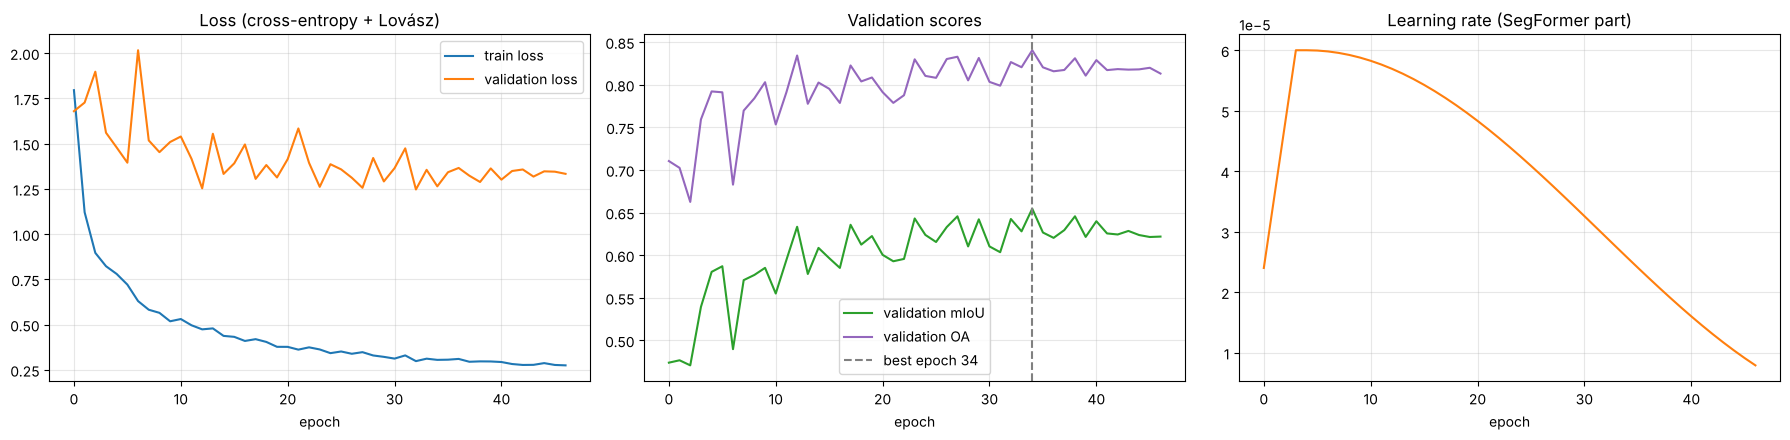

best epoch 34: validation mIoU 0.6545, OA 0.8404 | epochs run 47 (early stopping) | training time 53 min on an NVIDIA RTX A6000


In [3]:
best = int(hist.val_miou.idxmax())
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].plot(hist.epoch, hist.train_loss, label="train loss"); ax[0].plot(hist.epoch, hist.val_loss, label="validation loss")
ax[0].set_title("Loss (cross-entropy + Lovász)"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(hist.epoch, hist.val_miou, color="tab:green", label="validation mIoU")
ax[1].plot(hist.epoch, hist.val_oa, color="tab:purple", label="validation OA")
ax[1].axvline(hist.epoch[best], color="grey", ls="--", label=f"best epoch {hist.epoch[best]}")
ax[1].set_title("Validation scores"); ax[1].set_xlabel("epoch"); ax[1].legend()
ax[2].plot(hist.epoch, hist.lr, color="tab:orange"); ax[2].set_title("Learning rate (SegFormer part)"); ax[2].set_xlabel("epoch")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"best epoch {hist.epoch[best]}: validation mIoU {hist.val_miou[best]:.4f}, OA {hist.val_oa[best]:.4f} "
      f"| epochs run {len(hist)} (early stopping) | training time {hist.seconds.sum() / 60:.0f} min on an NVIDIA RTX A6000")

**Reading the curves:** training loss keeps falling while validation loss flattens after about 20 epochs, and validation mIoU
peaks and then stops improving → early stopping keeps the best checkpoint (`best.pth`) and avoids overfitting.

## 3. Results on validation and test

In [4]:
summary = pd.DataFrame({"validation": [M["val_oa"], M["val_miou"]], "test": [M["test_oa"], M["test_miou"]]},
                       index=["Overall accuracy (OA)", "mean IoU (mIoU)"])
display(summary.round(3))
val = pd.read_csv(RUN / "val_per_class.csv", index_col=0); test = pd.read_csv(RUN / "test_per_class.csv", index_col=0)
per_class = pd.concat({"validation": val, "test": test}, axis=1)
display(per_class.round(3))

,validation,test
Overall accuracy (OA),0.840,0.846
mean IoU (mIoU),0.654,0.738


validation          test       
                   IoU     F1    IoU     F1
Trees            0.413  0.584  0.694  0.819
Grass/Shrub      0.700  0.824  0.512  0.677
Cropland         0.733  0.846  0.722  0.839
Built-up         0.788  0.882  0.837  0.911
Bare             0.293  0.453  0.964  0.982
Water            0.765  0.867  0.837  0.911
Wetland          0.889  0.941  0.599  0.750
mean             0.654  0.771  0.738  0.841

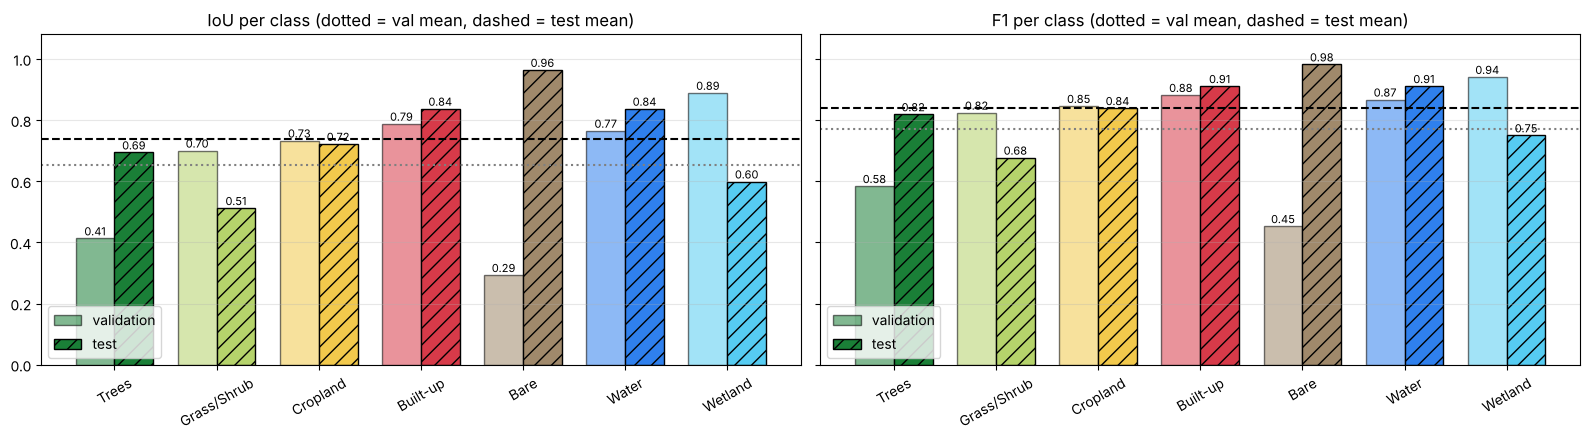

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
x = np.arange(len(CLASSES)); w = 0.38
for a, metric in zip(ax, ["IoU", "F1"]):
    a.bar(x - w / 2, val.loc[CLASSES, metric], w, color=COLORS, alpha=0.55, edgecolor="black", label="validation")
    a.bar(x + w / 2, test.loc[CLASSES, metric], w, color=COLORS, edgecolor="black", hatch="//", label="test")
    for i, c in enumerate(CLASSES):
        a.text(i - w / 2, val.loc[c, metric] + 0.01, f"{val.loc[c, metric]:.2f}", ha="center", fontsize=8)
        a.text(i + w / 2, test.loc[c, metric] + 0.01, f"{test.loc[c, metric]:.2f}", ha="center", fontsize=8)
    a.axhline(val.loc["mean", metric], color="grey", ls=":"); a.axhline(test.loc["mean", metric], color="black", ls="--")
    a.set_xticks(x, CLASSES, rotation=30); a.set_ylim(0, 1.08); a.set_title(f"{metric} per class (dotted = val mean, dashed = test mean)")
    a.legend(loc="lower left"); a.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

* **Strong:** Built-up, Water, Bare (test) and Cropland — classes with a clear radar signature or a clear seasonal pattern.
* **Weak:** Grass/Shrub and Wetland on test, Trees and Bare on validation. Bare is rare in the validation regions (1.6 % of
  pixels), so its validation IoU is unstable; the test regions contain large deserts (17 %), where Bare is almost perfect.
* Validation and test differ because they are different places (8 vs 6 regions on several continents): the gap shows how much
  the scores depend on the landscape.

## 4. Confusion matrices
Rows = WorldCover (true), columns = prediction, normalised per row (recall). Computed on the GPU during training (notebook 19).

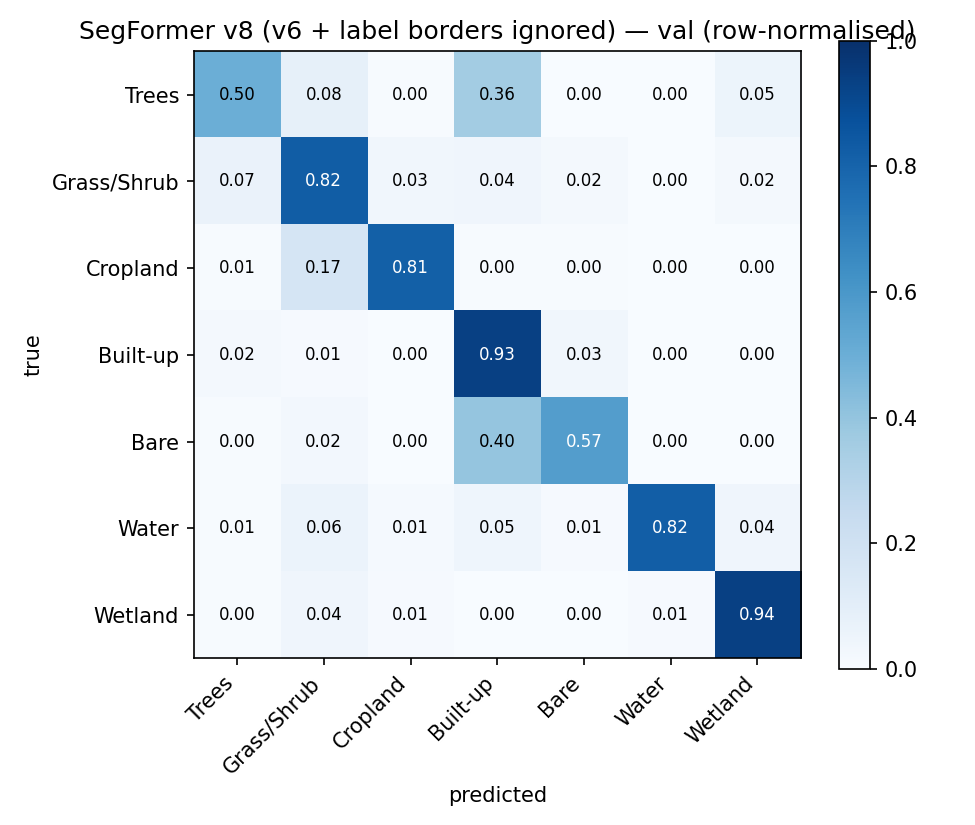

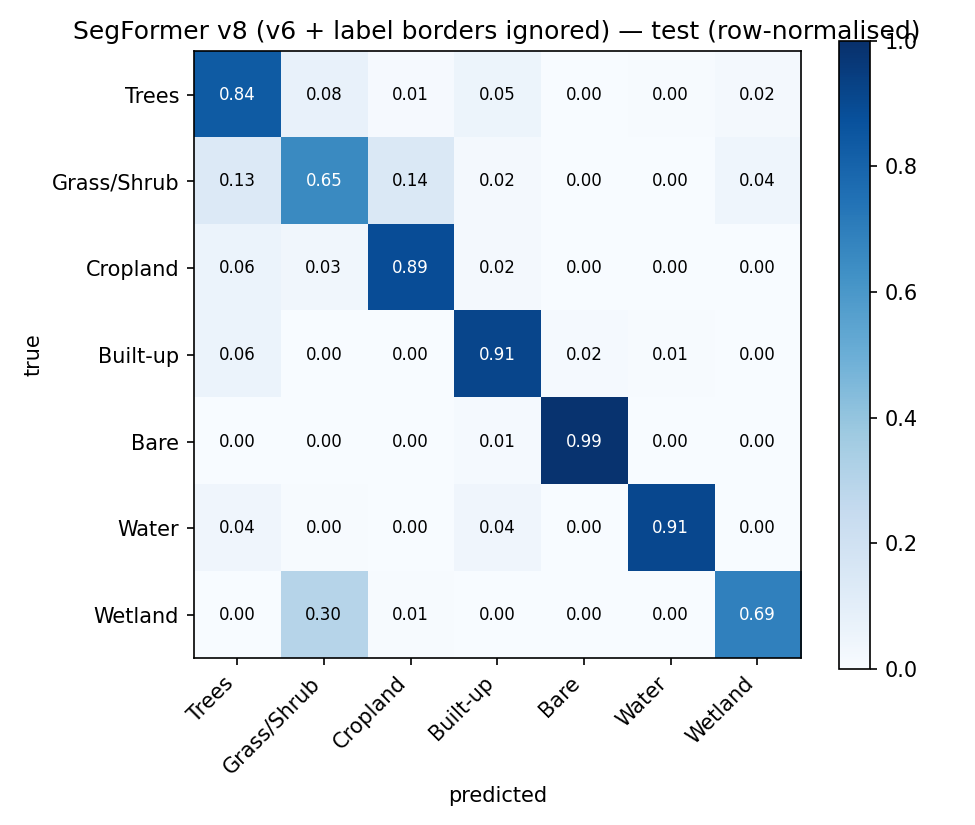

In [6]:
display(Image(filename=str(RUN / "val_confusion.png"), width=560)); display(Image(filename=str(RUN / "test_confusion.png"), width=560))

Main confusions: **Grass/Shrub ↔ Cropland** (both are low vegetation; a meadow and a field can look alike to radar),
**Trees ↔ Grass/Shrub** (open woodland, savanna), and **Wetland ↔ Water / Cropland** (flooded areas, rice paddies).
These are the classes where radar alone is physically ambiguous.

## 5. Stability over the 12 months
The prototype reports change between months, so the maps must not change just because the season changes
(e.g. a harvested field in winter is still cropland).

spread of mIoU between the 12 months: validation 0.0017, test 0.0076


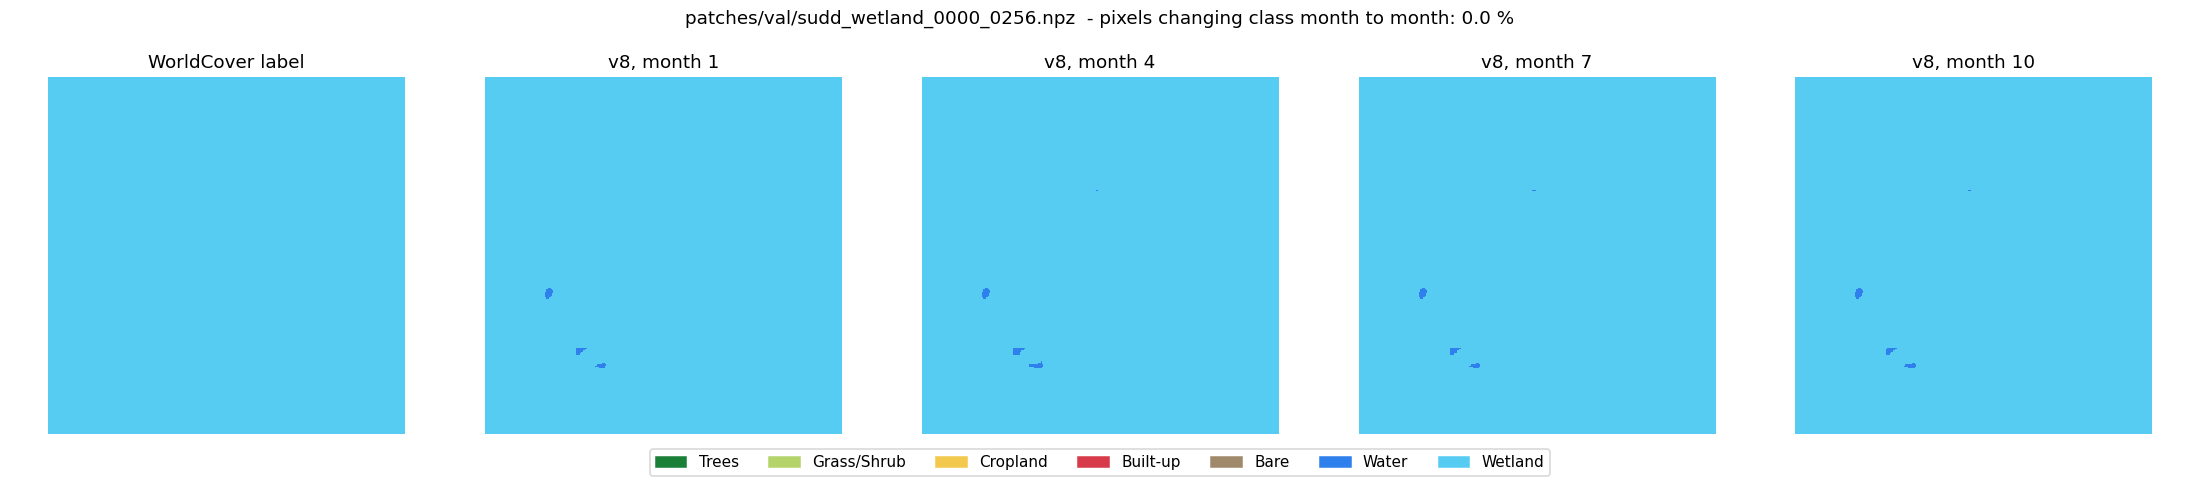

In [7]:
print(f"spread of mIoU between the 12 months: validation {M['val_month_spread']:.4f}, test {M['test_month_spread']:.4f}")
display(Image(filename=str(RUN / "val_months_example.png"), width=900))

The scores hardly differ between months (spread < 0.01): there is no winter dip, so seasonal effects do not show up as
fake land-cover change. The limitation is the other side of this: the model was trained with **one label per year**
(WorldCover 2021), so it is cautious about real changes inside a year.

## 6. What "ignore label borders" removes
WorldCover is least reliable on class boundaries (mixed 10 m pixels, 1-pixel shifts). In training, every pixel with another
class in its 3 × 3 neighbourhood is ignored; validation and test keep all pixels.

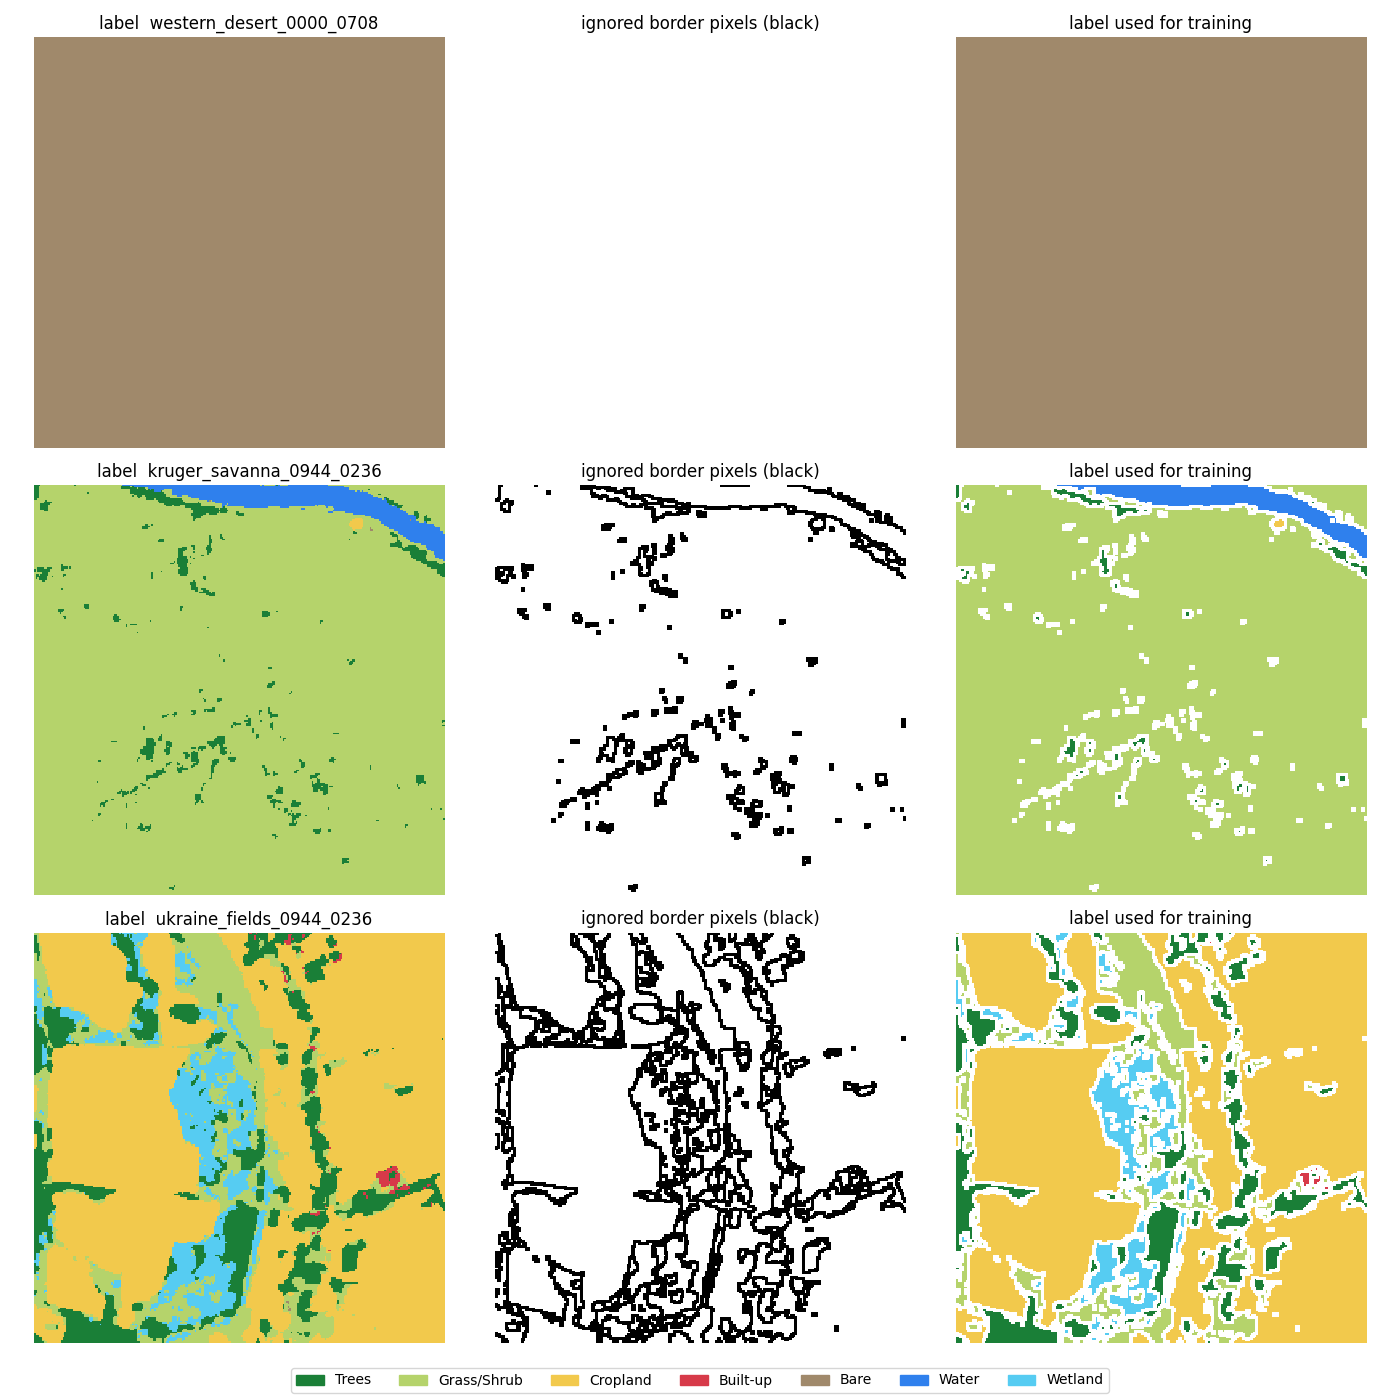

,pixels before,pixels after,ignored %,share before %,share after %
Trees,1502122.0,1070440.0,28.7,11.5,9.6
Grass/Shrub,2953807.0,2422279.0,18.0,22.5,21.8
Cropland,2134684.0,1922805.0,9.9,16.3,17.3
Built-up,2248725.0,1706763.0,24.1,17.2,15.4
Bare,1337306.0,1180100.0,11.8,10.2,10.6
Water,1537974.0,1499064.0,2.5,11.7,13.5
Wetland,1392582.0,1295860.0,6.9,10.6,11.7


In [8]:
display(Image(filename=str(RUN / "border_examples.png"), width=800))
display(pd.read_csv(RUN / "border_ignored_pixels.csv", index_col=0).round(1))

## 7. Comparison with the other models
All models are scored on the same 8 validation and 6 test regions (all tiles × 12 months).

In [9]:
rows = pd.read_csv("runs/comparison_r5/comparison_summary.csv", index_col=0)[["val OA", "val mIoU", "test OA", "test mIoU"]]
for run, name in [("C_segformer_v6", "SegFormer v6"), ("C_segformer_v7", "SegFormer v7"),
                  ("C_segformer_v8_border", "SegFormer v8 (final)"), ("A_unet_v8_border", "U-Net v8")]:
    m = json.load(open(f"runs/{run}/metrics.json"))
    rows.loc[run] = [m["val_oa"], m["val_miou"], m["test_oa"], m["test_miou"]]
nice = {"A_unet_resnet34": "U-Net v1", "B_deeplabv3plus_resnet50": "DeepLabV3+ v1", "C_segformer_mitb2": "SegFormer v1",
        "A_unet_v2": "U-Net v2", "B_deeplab_v2": "DeepLabV3+ v2", "C_segformer_v2": "SegFormer v2", "C_segformer_v3": "SegFormer v3",
        "A_unet_v4": "U-Net v4", "C_segformer_v4": "SegFormer v4", "A_unet_v4b": "U-Net v4b", "C_segformer_v4b": "SegFormer v4b",
        "C_segformer_v5": "SegFormer v5", "C_segformer_v5b": "SegFormer v5b", "C_segformer_v6": "SegFormer v6",
        "C_segformer_v7": "SegFormer v7", "C_segformer_v8_border": "SegFormer v8 (final)", "A_unet_v8_border": "U-Net v8"}
cmp = rows.rename(index=nice).sort_values("val mIoU", ascending=False)
display(cmp.round(3))

,val OA,val mIoU,test OA,test mIoU
SegFormer v8 (final),0.840,0.654,0.846,0.738
SegFormer v6,0.838,0.650,0.842,0.730
SegFormer v7,0.833,0.642,0.807,0.676
SegFormer v5,0.822,0.626,0.837,0.722
U-Net v8,0.815,0.616,0.801,0.668
SegFormer v4,0.804,0.613,0.811,0.690
SegFormer v5b,0.786,0.580,0.742,0.598
SegFormer v4b,0.782,0.570,0.764,0.636
U-Net v4,0.780,0.568,0.784,0.637
SegFormer v3,0.764,0.543,0.756,0.618


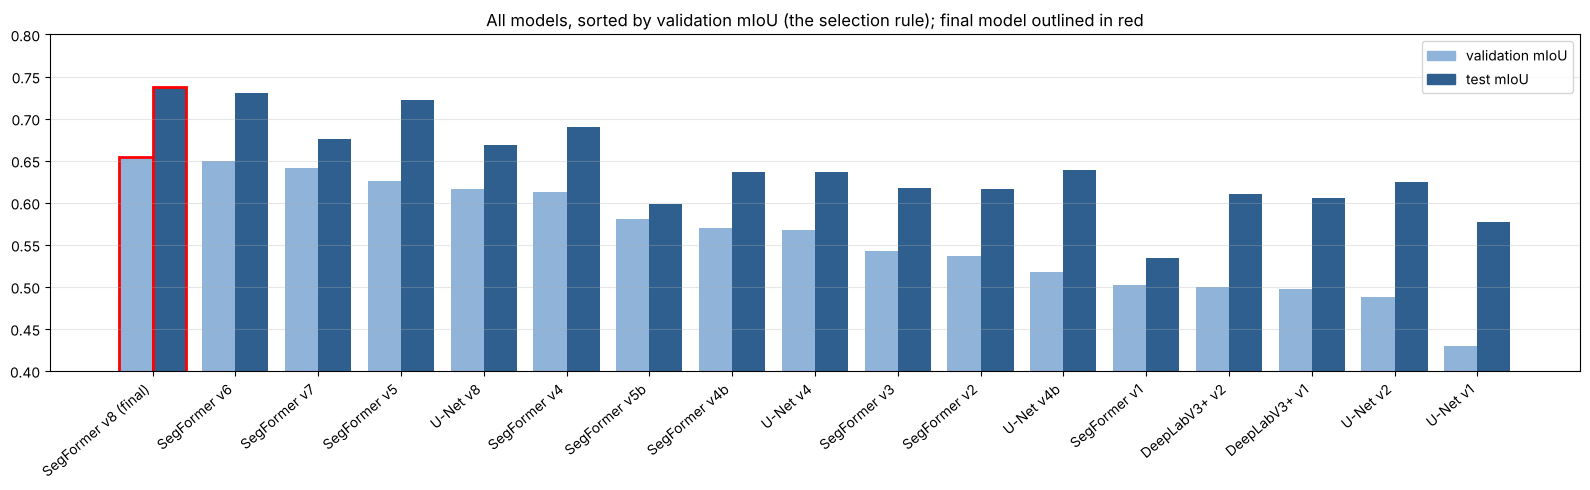

In [10]:
fig, ax = plt.subplots(figsize=(16, 5))
x = np.arange(len(cmp)); w = 0.4
ax.bar(x - w / 2, cmp["val mIoU"], w, label="validation mIoU", color="#8fb3d9")
ax.bar(x + w / 2, cmp["test mIoU"], w, label="test mIoU", color="#2f5f8f")
final = list(cmp.index).index("SegFormer v8 (final)")
ax.patches[final].set_edgecolor("red"); ax.patches[len(cmp) + final].set_edgecolor("red")
ax.patches[final].set_linewidth(2); ax.patches[len(cmp) + final].set_linewidth(2)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#8fb3d9", label="validation mIoU"), Patch(color="#2f5f8f", label="test mIoU")])
ax.set_xticks(x, cmp.index, rotation=40, ha="right"); ax.set_ylim(0.4, 0.8); ax.grid(axis="y", alpha=0.3)
ax.set_title("All models, sorted by validation mIoU (the selection rule); final model outlined in red")
plt.tight_layout(); plt.show()

## 8. How the model got here — round by round

,model,change,val mIoU,test mIoU
round,,,,
r2,SegFormer v1,"3 networks compared, same recipe",0.502,0.534
r3,SegFormer v3,"8 val regions, Lovász loss, regularisation",0.543,0.618
r4,SegFormer v4,+ year context (12-month mean / std),0.613,0.690
r5,SegFormer v5,+ 10 targeted training regions,0.626,0.722
r6,SegFormer v6,all 12 months + 18 year statistics,0.650,0.730
r7,SegFormer v7,+ 20 rice / wetland regions (not kept),0.642,0.676
r8,SegFormer v8,label borders ignored in training (final),0.654,0.738


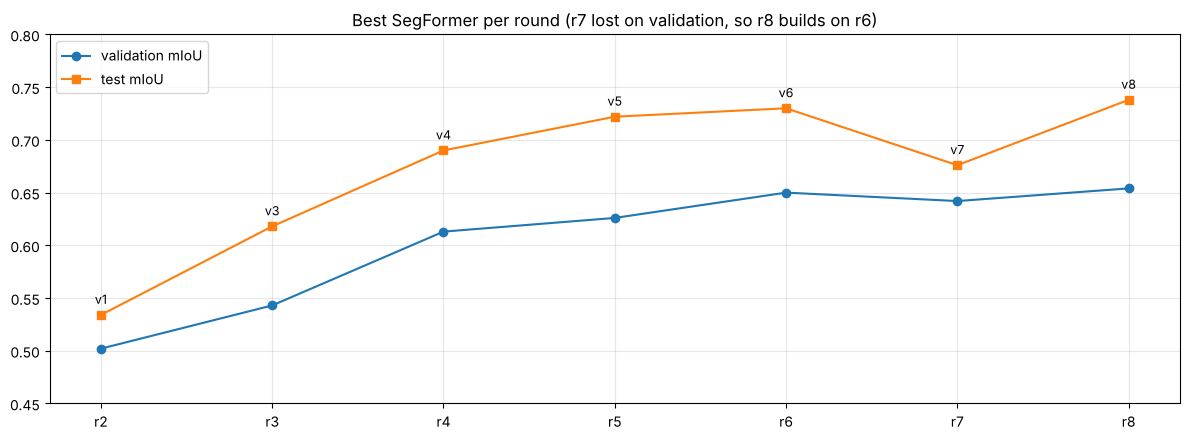

In [11]:
steps = pd.DataFrame([
    ("r2", "SegFormer v1", "3 networks compared, same recipe", 0.502, 0.534),
    ("r3", "SegFormer v3", "8 val regions, Lovász loss, regularisation", 0.543, 0.618),
    ("r4", "SegFormer v4", "+ year context (12-month mean / std)", 0.613, 0.690),
    ("r5", "SegFormer v5", "+ 10 targeted training regions", 0.626, 0.722),
    ("r6", "SegFormer v6", "all 12 months + 18 year statistics", 0.650, 0.730),
    ("r7", "SegFormer v7", "+ 20 rice / wetland regions (not kept)", 0.642, 0.676),
    ("r8", "SegFormer v8", "label borders ignored in training (final)", 0.654, 0.738),
], columns=["round", "model", "change", "val mIoU", "test mIoU"]).set_index("round")
display(steps)
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(steps.index, steps["val mIoU"], "o-", label="validation mIoU"); ax.plot(steps.index, steps["test mIoU"], "s-", label="test mIoU")
for r, row in steps.iterrows():
    ax.annotate(row["model"].replace("SegFormer ", ""), (r, row["test mIoU"]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.set_ylim(0.45, 0.8); ax.grid(alpha=0.3); ax.legend(); ax.set_title("Best SegFormer per round (r7 lost on validation, so r8 builds on r6)")
plt.tight_layout(); plt.show()

## 9. The trained weights
Loads `best.pth` into the model exactly as the prototype does. If the file is missing, download
[`weights_final.zip`](https://zenodo.org/records/24060094/files/weights_final.zip?download=1) and unzip it in the project folder.

In [12]:
import torch, train_lib_r8 as r8
W = RUN / "best.pth"
if W.exists():
    model = r8.build_model(cfg, json.load(open("data_r5/norm_stats.json")),
                           json.load(open("data_r5/norm_stats_r6_yearstats.json")), weights=None)
    model.load_state_dict(torch.load(W, map_location="cpu")); model.eval()
    n = sum(p.numel() for p in model.parameters())
    parts = {"temporal encoder": model.temporal, "fusion": model.fuse, "SegFormer MiT-B2": model.seg}
    print(f"weights loaded: {W} ({W.stat().st_size / 1e6:.0f} MB) | {n / 1e6:.1f} M parameters")
    display(pd.Series({k: sum(p.numel() for p in v.parameters()) for k, v in parts.items()}, name="parameters").to_frame())
else:
    model = None
    print("best.pth not found - download weights_final.zip from Zenodo (link above) and unzip it in the project folder")

weights loaded: runs/C_segformer_v8_border/best.pth (99 MB) | 24.8 M parameters


,parameters
temporal encoder,3960
fusion,3104
SegFormer MiT-B2,24814855


## 10. Example: 12 monthly maps of a test region
Runs the final model on the central 6 × 6 km of the **Mekong delta** test region (never used for training) and compares
with WorldCover. Needs `data/raw/mekong_delta_*` (from `raw_geotiffs.zip` on Zenodo); skipped otherwise.

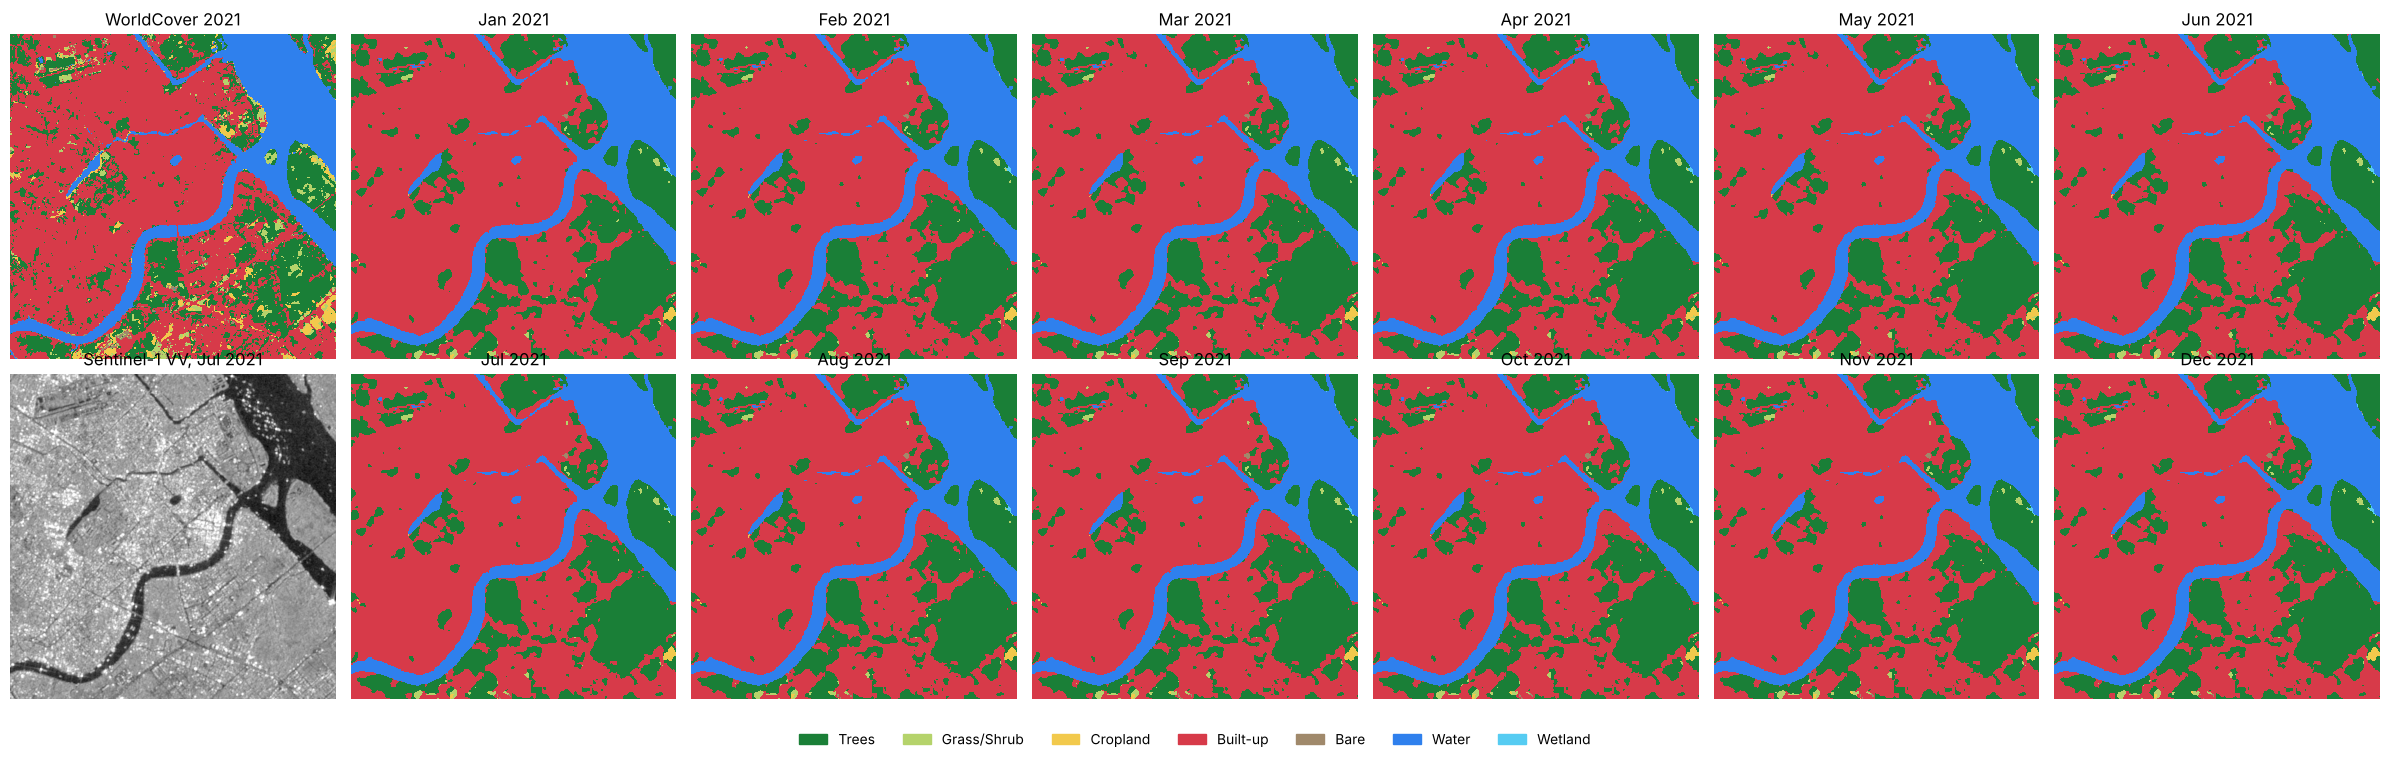

agreement with WorldCover per month (OA): [0.842, 0.842, 0.842, 0.842, 0.841, 0.841, 0.841, 0.842, 0.841, 0.841, 0.841, 0.842]


In [13]:
import rasterio, train_lib_r6 as r6
from matplotlib.colors import ListedColormap, BoundaryNorm
from preprocess import decode_s1, clip_db, remap_worldcover, IGNORE
S1, LAB = Path("data/raw/mekong_delta_s1_2021.tif"), Path("data/raw/mekong_delta_label.tif")
if model is not None and S1.exists() and LAB.exists():
    o, n = 300, 600                                             # central 6 km of the 12 km region
    with rasterio.open(S1) as f: raw = f.read()[:, o:o + n, o:o + n]
    with rasterio.open(LAB) as f: lab = remap_worldcover(f.read(1)[o:o + n, o:o + n])
    x12 = clip_db(decode_s1(raw.reshape(12, 3, n, n)))
    pred, conf = r6.predict_region(model, x12)
    cmap = ListedColormap(COLORS + ["#ffffff"]); norm = BoundaryNorm(list(range(8)) + [256], 8)
    fig, axs = plt.subplots(2, 7, figsize=(24, 7.5))
    axs[0, 0].imshow(np.where(lab == IGNORE, 7, lab), cmap=cmap, norm=norm, interpolation="nearest"); axs[0, 0].set_title("WorldCover 2021")
    axs[1, 0].imshow(x12[6, 0], cmap="gray", vmin=-25, vmax=5); axs[1, 0].set_title("Sentinel-1 VV, Jul 2021")
    for k, a in enumerate([a for i, row in enumerate(axs) for a in row[1:]]):
        a.imshow(np.where(pred[k] == IGNORE, 7, pred[k]), cmap=cmap, norm=norm, interpolation="nearest")
        a.set_title(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"][k] + " 2021")
    for a in axs.flat: a.axis("off")
    from matplotlib.patches import Patch
    fig.legend([Patch(color=c) for c in COLORS], CLASSES, loc="lower center", ncol=7, frameon=False)
    plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()
    ok = lab != IGNORE
    print("agreement with WorldCover per month (OA):", [round(float((pred[k][ok] == lab[ok]).mean()), 3) for k in range(12)])
else:
    print("skipped: weights or data/raw/mekong_delta_* not found")

## 11. Summary
* **SegFormer v8 is the final model:** validation mIoU **0.654** (OA 0.840), test mIoU **0.738** (OA **0.846**), 24.8 M parameters.
* The biggest gains came from **using time** (year context in r4, all 12 months in r6), then from **targeted training regions**
  (r5) and **cleaner training labels** (r8).
* **Limitations:** Grass/Shrub and Wetland remain the weakest classes; flooded rice paddies can be mapped as Wetland
  (v7 fixed rice but lost natural wetland); with one label per year the maps are stable but cautious about real change.
* The prototype (`prototype/app.py`) uses exactly this model and these weights.